# Reliability of a Steel Column under Dead, Variable and Imperfection Loads

__Paper:__ N. Kuschel and R. Rackwitz, "Two basic problems in reliability-based structural optimization", *Mathematical Methods of Operations Research* 46:309–333, 1997 [[1]][R1]

__Authors:__ Norbert Kuschel and Rüdiger Rackwitz, Technische Universität München, München, Germany

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes under half a minute (most of it the Monte Carlo failure probabilities).

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize, stats
import active_subspaces as ac
import steel_column_model as sm

SEED = 736                        # the only seed in this notebook (every rng= below)
t_start = time.perf_counter()
CONFIGS = ('benchmark', 'paper')
TITLES = {'benchmark': 'benchmark: (b, d, h) = (300, 20, 300) mm, E mean 210000 MPa',
          'paper': 'paper: (b, d, h) = (200, 17.5, 100) mm, E mean 21000 MPa'}
labels = [r'$F_s$', r'$P_1$', r'$P_2$', r'$P_3$', r'$B$', r'$D$', r'$H$', r'$F_0$', r'$E$']

### Summary

The second example of Kuschel and Rackwitz [[1]][R1] (Sec. 6, pp. 326–327) is a steel column of length 7500 mm whose yield-stress limit state $G$ depends on nine independent random inputs (yield stress, three loads, three section dimensions, initial deflection and Young's modulus, with lognormal, normal, Gumbel and Weibull marginals) at a design given by the means $(b, d, h)$ of the three section dimensions. We build two configurations: the widely used benchmark design $(300, 20, 300)$ mm with a mean Young's modulus of 210000 MPa [[3]][R3][[4]][R4], and the paper's own optimum for maximal cost 4000, $(200, 17.5, 100)$ mm, with the mean of $E$ = 21000 MPa as printed in the paper's table, which reproduces all ten of the paper's reliability indices to within 0.0042 but puts the column far beyond its Euler buckling load. With inputs scaled through their CDFs to standard normal variables and exact gradients on 2000 Monte Carlo samples per configuration, both have a one-dimensional active subspace ($\lambda_1/\lambda_2$ = 88.99 and 88.10) that is close to the FORM direction, and a linear function of the active variable has leave-one-out $R^2$ = 0.98772 and 0.98508; Monte Carlo puts the failure probability of the paper's design at $1.24\times10^{-3}$, 1.43 times the first-order (FORM) value.

### Active subspaces in brief

For a function $f(\mathbf u)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf u = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf u$ and is nearly constant along $\mathbf W_2^T\mathbf u$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015 [[2]][R2].

### The model

**Limit state** (p. 327, as printed). With $\mathscr P = P_1 + P_2 + P_3$,
$$
G(\mathbf x, \mathbf p) = F_s - \mathscr P\left(\frac{1}{\mathscr A_s} + \frac{F_0}{\mathscr M_s}\cdot\frac{\mathscr E_b}{\mathscr E_b - \mathscr P}\right),
$$
$$
\mathscr A_s = 2BD \ \text{(area of section)},\quad \mathscr M_s = BDH \ \text{(modulus of section)},\quad \mathscr M_i = \tfrac12 BDH^2 \ \text{(moment of inertia)},\quad \mathscr E_b = \frac{\pi^2 E \mathscr M_i}{s^2} \ \text{(Euler buckling load)},
$$
where $s$ is the column length, "a constant length of 7500 mm" (p. 326; the symbol $s$ is not defined on the page, and we read it as that length). $G$ is the yield stress minus the largest compressive stress: the axial stress $\mathscr P/\mathscr A_s$ plus the bending stress of the initial deflection $F_0$, amplified by the factor $\mathscr E_b/(\mathscr E_b - \mathscr P)$; $G \le 0$ is failure. The section formulas are those of two flanges of area $BD$ at distance $H$ with the web neglected ($\mathscr M_i = 2BD(H/2)^2$, $\mathscr M_s = \mathscr M_i/(H/2)$); this is our reading, the paper does not say so (it calls the profile "T-shaped", p. 327). The quantity of interest is $G$ in MPa.

**Inputs** ($m = 9$). The paper lists "the independent uncertain vector $\mathbf X = (F_s, P_1, P_2, P_3, B, D, H, F_0, E)$" (p. 326) with the table below (p. 326; "Mean/Standard derivation" as printed). The design ("cost") parameters $\mathbf p = (b, d, h)$ are the **means** of $B$, $D$, $H$ (table, p. 326); they are not random, and the paper varies them in its optimization within $200 \le b \le 400$, $10 \le d \le 30$, $100 \le h \le 500$ mm (p. 327). The column length is fixed. So the example has nine random inputs, three design variables and one constant; this data set fixes the design and studies the nine random inputs.

| input | symbol | distribution | mean / sd (p. 326) | units | used here |
|---|---|---|---|---|---|
| yield stress | $F_s$ | lognormal | 400 / 35 | MPa | as printed |
| dead weight load | $P_1$ | normal | 500000 / 50000 | N | as printed |
| variable load | $P_2$ | Gumbel | 600000 / 90000 | N | as printed (largest-value Gumbel) |
| variable load | $P_3$ | Gumbel | 600000 / 90000 | N | as printed (largest-value Gumbel) |
| flange breadth | $B$ | lognormal | $b$ / 3 | printed "N" | mm (the unit "N" is a misprint) |
| flange thickness | $D$ | lognormal | $d$ / 2 | mm | as printed |
| height of profile | $H$ | lognormal | $h$ / 5 | mm | as printed |
| initial deflection | $F_0$ | normal | 30 / 10 | mm | as printed |
| Young's modulus | $E$ | Weibull | 21000 / 4200 | MPa | 210000 / 4200 (benchmark) or 21000 / 4200 (paper) |

The paper does not give the Gumbel and Weibull parameterizations; we use the largest-value Gumbel (loads) and the two-parameter Weibull, each with the printed mean and standard deviation (`steel_column_model.Marginals`).

**Young's modulus.** A mean of 21000 MPa is a tenth of the modulus of steel (about 210000 MPa), and the benchmark page of Surjanovic and Bingham [[3]][R3] uses 210000 MPa (with the design $(b, d, h) = (300, 20, 300)$ mm, which it attributes to Eldred, Webster and Constantine [[4]][R4]; we have not checked those design values in that paper). With the table as printed ($E$ 21000 / 4200 MPa, $s$ = 7500 mm), FORM reproduces every reliability index of the table on p. 327; with $E$ 210000 / 4200 MPa it does not (both below). This does not identify $E$ by itself: $E$ enters $G$ only through $\mathscr E_b = \pi^2 E\mathscr M_i/s^2$, and the Weibull is a scale family, so only the distribution of $E/s^2$ is identifiable from the indices. For example $E$ with mean 210000 MPa and sd 42000 MPa together with $s = 7500\sqrt{10} \approx 23717$ mm gives the same $\mathscr E_b$ in distribution, hence the same $\beta$ at every design (a factor of 10 in the units of $\mathscr M_i$ would do the same). At the paper's designs, with the printed table, the Euler load is far below the applied load ($\mathscr E_b/\mathscr P$ = 0.038 at the means of the cost-4000 design), so the amplification factor $\mathscr E_b/(\mathscr E_b - \mathscr P)$ is small and *negative*: the bending term lowers the stress, larger initial deflection makes the column safer, and $G$ is in effect the axial-stress margin $F_s - \mathscr P/\mathscr A_s$. A column loaded above its Euler load would buckle, so this regime is outside the formula's meaning.

**Two configurations** (`steel_column_model.CONFIGS`), both this data set's choices:

* `benchmark`: $(b, d, h) = (300, 20, 300)$ mm and $E$ with mean 210000 MPa, sd 4200 MPa, the configuration of [[3]][R3]; the column is well below its Euler load ($\mathscr E_b/\mathscr P$ = 5.85 at the means). This is the physically meaningful study.
* `paper`: the paper's optimum for maximal cost 4000, $(b, d, h) = (200, 17.5, 100)$ mm (table, p. 327), with $E$ as printed (mean 21000 MPa); used to compare with the paper's reliability index $\beta^* = 3.132$.

**Scaling.** Every input is scaled through its CDF to a standard normal variable, $u_i = \Phi^{-1}(F_i(x_i))$, the standard space of FORM; $\mathbf u \sim N(\mathbf 0, \mathbf I_9)$, and $\partial G/\partial u_i = (\partial G/\partial x_i)\,(dx_i/du_i)$ because the inputs are independent.

In [2]:
print(f"{'input':5s} {'distribution':10s} {'mean (benchmark | paper)':>26s} {'sd':>9s}  units  description")
mb, mp = sm.means('benchmark'), sm.means('paper')
for j, n in enumerate(sm.NAMES):
    print(f'{n:5s} {sm.DISTRIBUTIONS[j]:10s} {mb[j]:12.6g} | {mp[j]:<11.6g} {sm.SD[j]:9.6g}  {sm.UNITS[j]:5s}  {sm.DESCRIPTIONS[j]}')
for c in CONFIGS:
    mg = sm.Marginals(c)
    x0 = sm.means(c)[None, :]
    Eb0, P0 = sm.euler_load(x0)[0], x0[0, 1:4].sum()
    print(f'\n{c}: Weibull shape k = {mg.wb_k:.4f}, scale = {mg.wb_lam:.2f} MPa for E')
    print(f'  at the input means: G = {sm.limit_state(x0)[0]:.3f} MPa, P/As = {P0 / (2 * x0[0, 4] * x0[0, 5]):.3f} MPa, '
          f'Eb = {Eb0:.4e} N, P = {P0:.4e} N, Eb/P = {Eb0 / P0:.4f}, amplification Eb/(Eb - P) = {Eb0 / (Eb0 - P0):.4f}')

input distribution   mean (benchmark | paper)        sd  units  description
Fs    lognormal           400 | 400                35  MPa    yield stress
P1    normal           500000 | 500000          50000  N      dead weight load
P2    gumbel           600000 | 600000          90000  N      variable load
P3    gumbel           600000 | 600000          90000  N      variable load
B     lognormal           300 | 200                 3  mm     flange breadth
D     lognormal            20 | 17.5                2  mm     flange thickness
H     lognormal           300 | 100                 5  mm     height of profile
F0    normal               30 | 30                 10  mm     initial deflection
E     weibull          210000 | 21000            4200  MPa    Young's modulus

benchmark: Weibull shape k = 63.4086, scale = 211877.37 MPa for E
  at the input means: G = 224.161 MPa, P/As = 141.667 MPa, Eb = 9.9486e+06 N, P = 1.7000e+06 N, Eb/P = 5.8521, amplification Eb/(Eb - P) = 1.2061

paper: We

At the input means the `benchmark` column has $G$ = 224.161 MPa, an axial stress of 141.667 MPa, and an amplification factor of 1.2061 ($\mathscr E_b/\mathscr P$ = 5.8521). The `paper` column has $\mathscr E_b/\mathscr P$ = 0.0379 and an amplification factor of −0.0394, so its margin, 162.888 MPa, is slightly *larger* than the axial-stress margin $400 - 242.857 = 157.143$ MPa. The Weibull shape of $E$ is 63.4086 (coefficient of variation 0.02) in `benchmark` and 5.7974 (coefficient of variation 0.2) in `paper`.

### Load data

`generate_data.py` drew, for each configuration, $M = 2000$ independent Monte Carlo samples $\mathbf u \sim N(\mathbf 0, \mathbf I_9)$ (`numpy.random.default_rng`, seeds 736 and 1997), mapped them to physical inputs through the inverse CDFs, and wrote the physical inputs, $G$ and the exact gradient $\partial G/\partial\mathbf x$ (closed form, `steel_column_model.limit_state`).

In [3]:
data = {}
for c in CONFIGS:
    X = np.loadtxt(f'{c}_inputs.csv', delimiter=',')        # (M, 9) physical inputs
    f = np.loadtxt(f'{c}_outputs.csv', delimiter=',')       # (M,)   G (MPa)
    dGdx = np.loadtxt(f'{c}_gradients.csv', delimiter=',')  # (M, 9) dG/dx, physical inputs
    data[c] = {'X': X, 'f': f, 'dGdx': dGdx}
    print(f'{c}: inputs {X.shape}, outputs {f.shape}, gradients {dGdx.shape}')

benchmark: inputs (2000, 9), outputs (2000,), gradients (2000, 9)
paper: inputs (2000, 9), outputs (2000,), gradients (2000, 9)


We map the inputs back to $\mathbf u$ and the gradients to $\partial G/\partial\mathbf u$, check the files against the model and the gradients against central differences in $\mathbf u$ (an independent computation), and count samples outside physical meaning.

In [4]:
for c in CONFIGS:
    X, f, dGdx = data[c]['X'], data[c]['f'], data[c]['dGdx']
    mg = sm.Marginals(c)
    U = mg.u_from_x(X)                                  # standard normal coordinates u = Phi^-1(F(x))
    Gu = dGdx * mg.dx_du(U)                             # dG/du = dG/dx * dx/du (diagonal Jacobian)
    data[c]['U'], data[c]['Gu'] = U, Gu
    h = 1e-6
    fd = np.column_stack([(sm.limit_state_u(U + h * np.eye(9)[j], c) - sm.limit_state_u(U - h * np.eye(9)[j], c)) / (2 * h)
                          for j in range(9)])
    err = np.linalg.norm(fd - Gu, axis=1) / np.linalg.norm(Gu, axis=1)
    EbP = sm.euler_load(X) / X[:, 1:4].sum(axis=1)
    print(f'{c}:')
    print(f'  max |model - file| / |file| = {np.max(np.abs(sm.limit_state(X) - f) / np.abs(f)):.1e}; '
          f'max |x(u(x)) - x| / |x| = {np.max(np.abs(mg.x_from_u(U) - X) / np.abs(X)):.1e}')
    print(f'  dG/du vs central differences in u (h = 1e-6), all {len(X)} rows: max relative error {err.max():.1e}')
    print(f'  sample mean of u: max |.| = {np.abs(U.mean(0)).max():.3f}; sample sd of u in [{U.std(0, ddof=1).min():.3f}, {U.std(0, ddof=1).max():.3f}]')
    print(f'  G in [{f.min():.3f}, {f.max():.3f}] MPa; samples with G <= 0: {int(np.sum(f <= 0))}; '
          f'Eb/P in [{EbP.min():.4f}, {EbP.max():.4f}]; samples with Eb < P: {int(np.sum(EbP < 1))}')
    print(f'  samples with F0 < 0 (normal initial deflection): {int(np.sum(X[:, 7] < 0))}; with P1 <= 0: {int(np.sum(X[:, 1] <= 0))}')
    # G depends on B and D only through B*D: dG/dlnB = dG/dlnD
    r = np.max(np.abs(dGdx[:, 4] * X[:, 4] - dGdx[:, 5] * X[:, 5]) / np.abs(dGdx[:, 5] * X[:, 5]))
    print(f'  max |B dG/dB - D dG/dD| / |D dG/dD| = {r:.1e}')

benchmark:
  max |model - file| / |file| = 0.0e+00; max |x(u(x)) - x| / |x| = 2.7e-16
  dG/du vs central differences in u (h = 1e-6), all 2000 rows: max relative error 5.3e-09
  sample mean of u: max |.| = 0.033; sample sd of u in [0.977, 1.020]
  G in [14.537, 377.933] MPa; samples with G <= 0: 0; Eb/P in [3.7168, 9.3322]; samples with Eb < P: 0
  samples with F0 < 0 (normal initial deflection): 5; with P1 <= 0: 0
  max |B dG/dB - D dG/dD| / |D dG/dD| = 3.3e-16
paper:
  max |model - file| / |file| = 0.0e+00; max |x(u(x)) - x| / |x| = 3.6e-16
  dG/du vs central differences in u (h = 1e-6), all 2000 rows: max relative error 4.7e-09
  sample mean of u: max |.| = 0.044; sample sd of u in [0.998, 1.029]
  G in [-31.406, 328.842] MPa; samples with G <= 0: 2; Eb/P in [0.0090, 0.0816]; samples with Eb < P: 2000
  samples with F0 < 0 (normal initial deflection): 5; with P1 <= 0: 0
  max |B dG/dB - D dG/dD| / |D dG/dD| = 2.9e-16


The files match the model to round-off (relative differences below $10^{-15}$), the maps $x(u)$ and $u(x)$ invert each other to order $10^{-16}$, and the gradients agree with central differences to $5.3\times10^{-9}$ (`benchmark`) and $4.7\times10^{-9}$ (`paper`), the size of the differencing error. Five samples in each configuration have a negative initial deflection $F_0$ (a normal with mean 30 mm and sd 10 mm); the printed formula uses $F_0$ and not $|F_0|$, so for these samples $G$ is the stress margin of the less-stressed side; we keep them, as the formula is printed (5 of 2000). No `benchmark` sample reaches its Euler load ($\mathscr E_b/\mathscr P \in [3.7168, 9.3322]$) and none fails ($G \ge 14.537$ MPa); **every** `paper` sample is above its Euler load ($\mathscr E_b/\mathscr P \le 0.0816$), as discussed above, and 2 of its 2000 samples fail. $G$ depends on $B$ and $D$ only through the product $BD$, so $B\,\partial G/\partial B = D\,\partial G/\partial D$ (to order $10^{-16}$); in $\mathbf u$ this gives an exact null direction, $s_D\mathbf e_B - s_B\mathbf e_D$ with $s_B, s_D$ the log-standard deviations.

### Estimate the active subspace

We have exact gradients, so we use the gradient-based estimator (`estimator='as'`), the average of $\nabla_{\mathbf u} G\,\nabla_{\mathbf u} G^T$ over the 2000 samples, on the space $N(\mathbf 0, \mathbf I_9)$, with 500 bootstrap replicates. The sign of each eigenvector is set so that the mean gradient has a positive component along it (`ac.orient(..., by='mean_gradient')`): $G$ increases, the column gets safer, along $\mathbf w_1$. The paper has no active-subspace figures to match.

In [5]:
space = ac.Gaussian(np.zeros(9), np.ones(9), names=list(sm.NAMES))   # u ~ N(0, I_9)
subs = {}
for c in CONFIGS:
    s = ac.active_subspace(space=space, X=data[c]['U'], grads=data[c]['Gu'], estimator='as', n=1, nboot=500, rng=SEED)
    subs[c] = ac.orient(s, by='mean_gradient', grads=data[c]['Gu'])
    lam = subs[c].eigenvalues
    C_u = data[c]['Gu'].T @ data[c]['Gu'] / len(data[c]['Gu'])
    lam_np = np.linalg.eigvalsh(C_u)[::-1]
    print(f'{c}: eigenvalues', np.array2string(lam, precision=4))
    print(f'  ratios lambda_k/lambda_k+1 (k = 1..7):', np.array2string(lam[:7] / lam[1:8], precision=2))
    print(f'  numpy eigvalsh of the same matrix: lambda_9 = {lam_np[8]:.1e}, lambda_9/lambda_1 = {lam_np[8] / lam_np[0]:.1e}')
    print(f'  share of the trace outside w1: {lam[1:].sum() / lam.sum():.4f}; outside w1, w2: {lam[2:].sum() / lam.sum():.4f}')
    print(f'  bootstrap mean subspace distance, n = 1..4:', np.array2string(subs[c].bootstrap_distances.mean(axis=0)[:4], precision=4))

benchmark: eigenvalues [1.9299e+03 2.1686e+01 1.2113e+01 2.6179e+00 6.5882e-01 3.7420e-02
 7.3831e-03 2.7332e-03 4.3143e-31]
  ratios lambda_k/lambda_k+1 (k = 1..7): [88.99  1.79  4.63  3.97 17.61  5.07  2.7 ]
  numpy eigvalsh of the same matrix: lambda_9 = 1.4e-15, lambda_9/lambda_1 = 7.3e-19
  share of the trace outside w1: 0.0189; outside w1, w2: 0.0078
  bootstrap mean subspace distance, n = 1..4: [0.0029 0.0434 0.0173 0.0154]


paper: eigenvalues [2.4436e+03 2.7736e+01 2.2783e+01 4.4350e+00 2.2723e-01 1.7839e-01
 7.3912e-02 2.4929e-03 2.8046e-30]
  ratios lambda_k/lambda_k+1 (k = 1..7): [88.1   1.22  5.14 19.52  1.27  2.41 29.65]
  numpy eigvalsh of the same matrix: lambda_9 = -1.0e-15, lambda_9/lambda_1 = -4.3e-19
  share of the trace outside w1: 0.0222; outside w1, w2: 0.0111
  bootstrap mean subspace distance, n = 1..4: [0.0033 0.1209 0.0171 0.008 ]


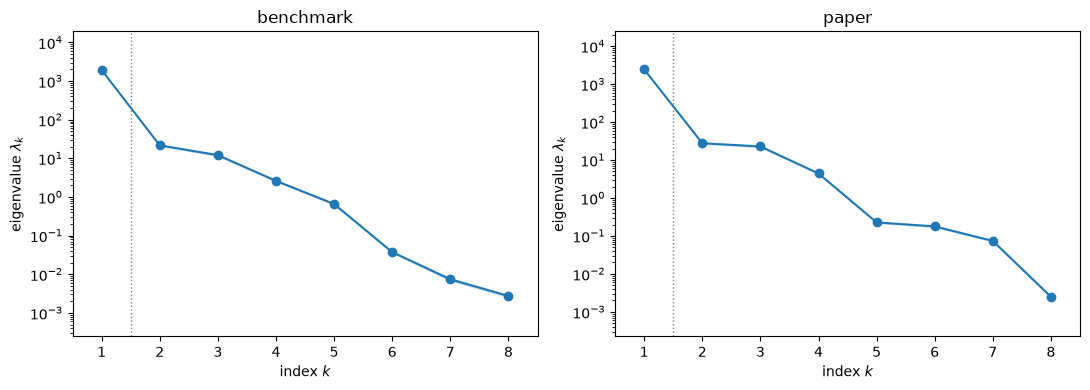

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, CONFIGS):
    ac.plotting.plot_eigenvalues(subs[c], k_max=8, ax=ax)
    ax.set_title(c)
fig.tight_layout()
plt.close(fig)
fig

Both configurations have one dominant eigenvalue: $\lambda_1/\lambda_2$ = 88.99 (`benchmark`) and 88.10 (`paper`), and the eigenvalues after the first carry 0.0189 and 0.0222 of the trace. The next ratios are small ($\lambda_2/\lambda_3$ = 1.79 and 1.22), so no second gap follows. The smallest eigenvalue is at the round-off level (of order $10^{-15}$ in magnitude from numpy, below $10^{-18}$ of $\lambda_1$; the library reports it as of order $10^{-31}$ and $10^{-30}$), the null direction of $BD$; it is off the plotted range.

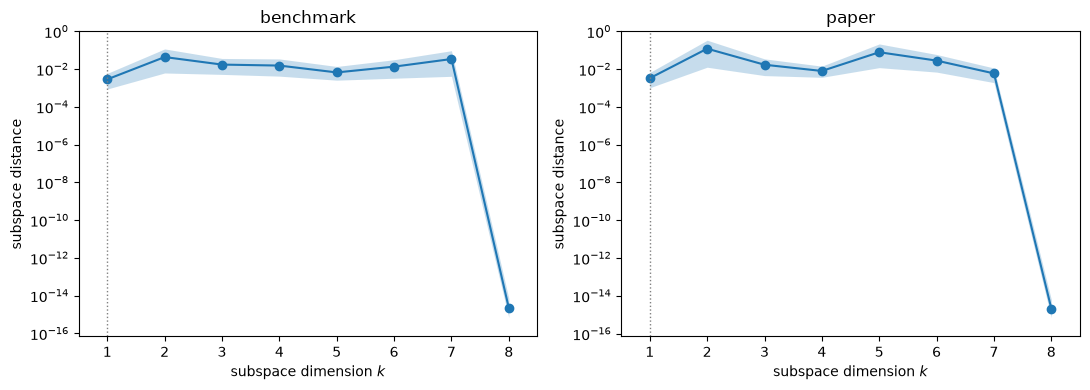

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, CONFIGS):
    ac.plotting.plot_subspace_errors(subs[c], k_max=8, ax=ax)
    ax.set_title(c)
fig.tight_layout()
plt.close(fig)
fig

The bootstrap mean subspace distance for $n = 1$ is 0.0029 (`benchmark`) and 0.0033 (`paper`), against 0.0434 and 0.1209 for $n = 2$: the first eigenvector is well determined by 2000 samples, and the second is not separated from the third.

benchmark:
         Fs       P1       P2       P3        B        D        H       F0        E
w1   0.7984  -0.1237  -0.2199  -0.2198   0.0423   0.4224   0.0190  -0.2645   0.0034
w2   0.5647   0.0495   0.4921   0.4647  -0.0407  -0.4060  -0.0427   0.2282  -0.0106
w9  -0.0000  -0.0000  -0.0000   0.0000   0.9950  -0.0997   0.0000  -0.0000   0.0000
  |w9 . (s_D e_B - s_B e_D)/norm| = 1.000000
paper:
         Fs       P1       P2       P3        B        D        H       F0        E
w1   0.7067  -0.1473  -0.2641  -0.2642   0.0758   0.5758   0.0063   0.0385   0.0239
w2   0.6318  -0.0045   0.5328   0.4629  -0.0417  -0.3165   0.0043   0.0217   0.0158
w9   0.0000   0.0000   0.0000  -0.0000   0.9914  -0.1305  -0.0000  -0.0000  -0.0000
  |w9 . (s_D e_B - s_B e_D)/norm| = 1.000000


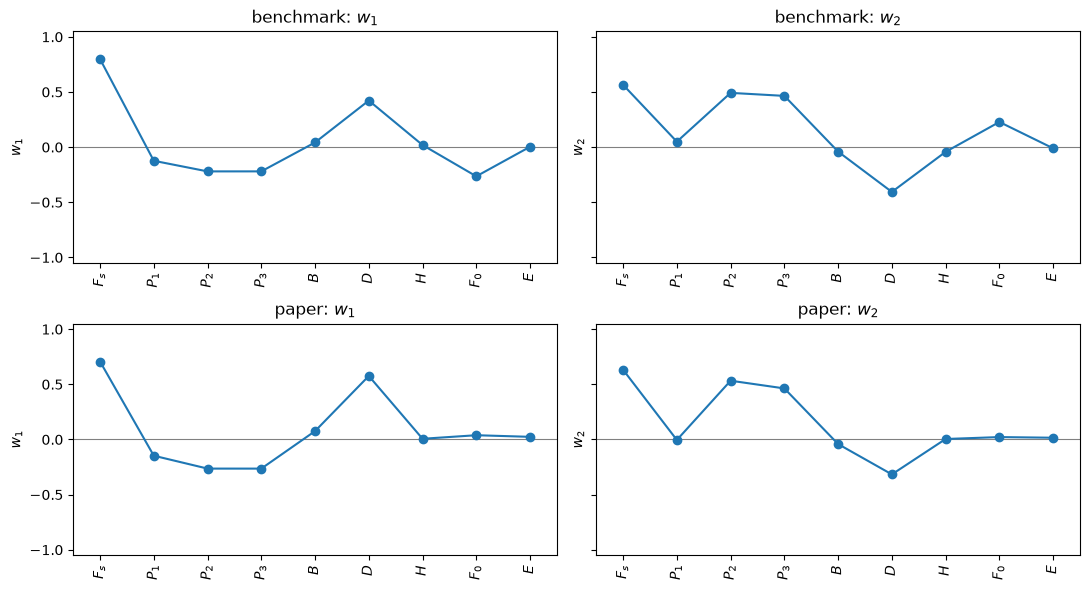

In [8]:
for c in CONFIGS:
    W = subs[c].W
    print(f'{c}:')
    print('   ' + ' '.join(f'{n:>8s}' for n in sm.NAMES))
    print('w1 ' + ' '.join(f'{v:8.4f}' for v in W[:, 0]))
    print('w2 ' + ' '.join(f'{v:8.4f}' for v in W[:, 1]))
    print(f'w9 ' + ' '.join(f'{v:8.4f}' for v in W[:, 8]))
    sB, sD = sm.Marginals(c).ln_s[4], sm.Marginals(c).ln_s[5]
    null = np.zeros(9); null[4], null[5] = sD, -sB
    print(f'  |w9 . (s_D e_B - s_B e_D)/norm| = {abs(W[:, 8] @ null) / np.linalg.norm(null):.6f}')
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
for i, c in enumerate(CONFIGS):
    ac.plotting.plot_eigenvectors(subs[c], indices=[0, 1], labels=labels, ax=axes[i])
    axes[i][0].set_title(f'{c}: $w_1$')
    axes[i][1].set_title(f'{c}: $w_2$')
    for ax in axes[i]:
        ax.set_xticks(axes[i][1].get_xticks())
        ax.set_xticklabels(labels, rotation=90)
        ax.tick_params(labelbottom=True)
fig.tight_layout()
plt.close(fig)
fig

In the `benchmark` configuration $\mathbf w_1$ = (0.7984, −0.1237, −0.2199, −0.2198, 0.0423, 0.4224, 0.0190, −0.2645, 0.0034): yield stress first, then flange thickness, the two variable loads and the initial deflection; the dead load enters less than the variable loads because its sd is smaller (50000 against 90000 N), and $B$, $H$ and $E$ matter little because their coefficients of variation are 1–2 %. In the `paper` configuration the initial deflection drops out of $\mathbf w_1$ (0.0385, and positive: a larger bow is *safer*, the sign of the negative amplification) and the weight moves to $F_s$, $D$ and the loads, as expected for the axial-stress margin $F_s - \mathscr P/(2BD)$. In both, $\mathbf w_9$ is the $BD$ null direction (inner product 1.000000).

**Comparison with FORM.** FORM, the method of the paper (abstract, p. 309), finds the point of $\{G = 0\}$ closest to the origin in $\mathbf u$; its distance is the reliability index $\beta$ and $\boldsymbol\alpha = -\mathbf u^*/\beta$ is the unit vector of the linearized limit state. We compute it with SLSQP and the exact gradients.

In [9]:
def form(config, starts=(0.1, 0.2, 0.05)):
    # FORM: closest point of {G = 0} to the origin in u (SLSQP with exact gradients); the index is
    # signed (negative when G < 0 at u = 0). Tries the starting points u = (t, ..., t) in turn and
    # returns (nan, None) if SLSQP reports no convergence from any of them.
    cons = {'type': 'eq', 'fun': lambda u: sm.limit_state_u(u, config)[0],
            'jac': lambda u: sm.limit_state_u(u, config, grad=True)[1][0]}
    sign = np.sign(sm.limit_state_u(np.zeros(9), config)[0])
    for t in starts:
        r = optimize.minimize(lambda u: u @ u, np.full(9, t), jac=lambda u: 2 * u, method='SLSQP',
                              constraints=[cons], options={'ftol': 1e-14, 'maxiter': 1000})
        if r.success:
            return sign * np.sqrt(r.fun), r.x
    return np.nan, None
form_res = {}
for c in CONFIGS:
    beta, ustar = form(c)
    assert ustar is not None
    alpha = -ustar / beta                                # unit vector from the design point to the origin
    form_res[c] = (beta, ustar)
    print(f'{c}: FORM beta = {beta:.4f}, Phi(-beta) = {stats.norm.cdf(-beta):.4e}; |w1 . alpha| = {abs(subs[c].W[:, 0] @ alpha):.4f}')
    print('   alpha ' + ' '.join(f'{v:8.4f}' for v in alpha))

benchmark: FORM beta = 4.5958, Phi(-beta) = 2.1550e-06; |w1 . alpha| = 0.8786
   alpha   0.4361  -0.1287  -0.4300  -0.4300   0.0558   0.5570   0.0444  -0.3286   0.0109


paper: FORM beta = 3.1321, Phi(-beta) = 8.6783e-04; |w1 . alpha| = 0.9623
   alpha   0.4991  -0.1504  -0.3753  -0.3753   0.0871   0.6616   0.0048   0.0311   0.0188


FORM gives $\beta$ = 3.1321 for the `paper` configuration (the paper prints 3.132, p. 327) and 4.5958 for `benchmark` (not in the paper). The active direction is close to the FORM direction: $|\mathbf w_1\cdot\boldsymbol\alpha|$ = 0.9623 (`paper`) and 0.8786 (`benchmark`). They need not coincide: $\mathbf w_1$ averages the gradient over the whole input distribution, while $\boldsymbol\alpha$ is the gradient direction at the design point, about 4.6 standard deviations out in `benchmark`, where the Gumbel loads weigh more (components −0.4300 against −0.2199 in $\mathbf w_1$).

In [10]:
paper_table = [  # (C_max, b*, d*, h*, beta*), table on p. 327
    (4000, 200.00, 17.50, 100.00, 3.132), (5000, 200.00, 22.50, 100.00, 4.961),
    (6000, 200.00, 27.50, 100.00, 6.369), (7000, 216.67, 30.00, 100.00, 7.427),
    (8000, 250.00, 30.00, 100.00, 8.249), (9000, 283.33, 30.00, 100.00, 8.967),
    (10000, 316.67, 30.00, 100.00, 9.605), (11000, 350.00, 30.00, 100.00, 10.180),
    (12000, 383.33, 30.00, 100.00, 10.709), (13000, 400.00, 30.00, 200.00, 11.065)]
print(' C_max      b*     d*     h*   beta* (p. 327)   FORM, E 21000   diff   FORM, E 210000   Eb/P at means (E 21000 | 210000)')
diffs, diffs210 = [], []
for cmax, b, d, h, beta_p in paper_table:
    beta = form({'b': b, 'd': d, 'h': h, 'E_mean': 21000.0})[0]
    beta210 = form({'b': b, 'd': d, 'h': h, 'E_mean': 210000.0})[0]
    diffs.append(beta - beta_p)
    diffs210.append(beta210 - beta_p)
    ebp = []
    for Em in (21000.0, 210000.0):
        x = sm.means({'b': b, 'd': d, 'h': h, 'E_mean': Em})[None, :]
        ebp.append(sm.euler_load(x)[0] / x[0, 1:4].sum())
    b210 = f'{beta210:9.4f}' if np.isfinite(beta210) else 'no conv.'
    print(f'{cmax:6d} {b:7.2f} {d:6.2f} {h:6.2f}   {beta_p:9.3f}      {beta:9.4f}     {beta - beta_p:+.4f}   {b210:>9s}        {ebp[0]:.3f} | {ebp[1]:.3f}')
print(f'E mean 21000:  largest |FORM - beta*| = {np.max(np.abs(diffs)):.4f}')
d210 = np.array(diffs210)
print(f'E mean 210000: converged at {int(np.sum(np.isfinite(d210)))} of 10 designs; |FORM - beta*| from '
      f'{np.nanmin(np.abs(d210)):.3f} to {np.nanmax(np.abs(d210)):.3f}')
# E enters only through Eb = pi^2 E Mi / s^2, and the Weibull is a scale family:
k1, l1 = sm._weibull_params(21000.0, 4200.0)
k2, l2 = sm._weibull_params(210000.0, 42000.0)
print(f'Weibull (mean, sd) = (21000, 4200): k = {k1:.4f}, scale = {l1:.2f}; (210000, 42000): k = {k2:.4f}, scale = {l2:.2f}; '
      f'scale ratio {l2 / l1:.6f}; shapes to 10 decimals: {k1:.10f}, {k2:.10f}')


 C_max      b*     d*     h*   beta* (p. 327)   FORM, E 21000   diff   FORM, E 210000   Eb/P at means (E 21000 | 210000)


  4000  200.00  17.50 100.00       3.132         3.1321     +0.0001      3.9109        0.038 | 0.379
  5000  200.00  22.50 100.00       4.961         4.9614     +0.0004      5.6596        0.049 | 0.488


  6000  200.00  27.50 100.00       6.369         6.3694     +0.0004      4.4822        0.060 | 0.596


  7000  216.67  30.00 100.00       7.427         7.4269     -0.0001      3.4315        0.070 | 0.704


  8000  250.00  30.00 100.00       8.249         8.2491     +0.0001    no conv.        0.081 | 0.813
  9000  283.33  30.00 100.00       8.967         8.9662     -0.0008      1.5736        0.092 | 0.921
 10000  316.67  30.00 100.00       9.605         9.6042     -0.0008     -0.7975        0.103 | 1.030
 11000  350.00  30.00 100.00      10.180        10.1797     -0.0003     -0.1009        0.114 | 1.138


 12000  383.33  30.00 100.00      10.709        10.7048     -0.0042      0.5288        0.125 | 1.246


 13000  400.00  30.00 200.00      11.065        11.0646     -0.0004    no conv.        0.520 | 5.202
E mean 21000:  largest |FORM - beta*| = 0.0042
E mean 210000: converged at 8 of 10 designs; |FORM - beta*| from 0.699 to 10.402
Weibull (mean, sd) = (21000, 4200): k = 5.7974, scale = 22679.48; (210000, 42000): k = 5.7974, scale = 226794.82; scale ratio 10.000000; shapes to 10 decimals: 5.7974000657, 5.7974000657


With the mean of $E$ as printed (21000 MPa), FORM here reproduces the paper's ten reliability indices to within 0.0042 (the largest gap, at cost 12000; the others are within 0.0008). With $E$ mean 210000 MPa and sd 4200 MPa it does not: SLSQP converges at 8 of the 10 designs, and there the indices differ from the paper's by 0.699 to 10.402 (3.9109 against 3.132 at cost 4000, 4.4822 against 6.369 at cost 6000, and −0.7975 against 9.605 at cost 10000, a negative index because $G < 0$ at $\mathbf u = \mathbf 0$, the input medians; no convergence at costs 8000 and 13000). These designs straddle the pole of the amplification factor ($\mathscr E_b/\mathscr P$ at the means from 0.379 to 5.202), so with this value of $E$ the limit state is singular inside the input distribution. With $E$ = 21000 MPa every design is beyond its Euler load at the means ($\mathscr E_b/\mathscr P$ from 0.038 to 0.520). So the printed table reproduces $\beta^*$ and $E$ 210000 / 4200 MPa does not. Only the distribution of $E/s^2$ is identified: the Weibull with mean 210000 and sd 42000 MPa has the same shape (5.7974) as the one with mean 21000 and sd 4200 MPa and a scale 10.000000 times larger, so with $s^2$ ten times larger it gives the same $\mathscr E_b$ and the same $\beta$ at every design. Whether the authors used $E$ = 21000 MPa, a different $s$, or different units for $\mathscr M_i$ cannot be told from the indices.

**Why $h^*$ stays at 100 mm.** The optimal mean height stays at its lower bound up to a cost of 12000 in the table (p. 327); the text says "up to a maximum cost of 12 500 CU" (p. 328). We check why along the cost constraint $bd + 5h = C_{\max}$ (cost, p. 326; $E$ as printed): at $C_{\max} = 4000$ we keep $b = 200$ and set $d = (4000 - 5h)/200$, and at $C_{\max} = 12000$ we keep $d = 30$ and set $b = (12000 - 5h)/30$, for $h$ from 100 to 200 mm.

In [11]:
print(' C_max       b       d       h   FORM beta   Eb/P at means')
for cmax in (4000, 12000):
    for h in (100.0, 110.0, 130.0, 200.0):
        b, d = (200.0, (cmax - 5 * h) / 200.0) if cmax == 4000 else ((cmax - 5 * h) / 30.0, 30.0)
        cfg = {'b': b, 'd': d, 'h': h, 'E_mean': 21000.0}
        x = sm.means(cfg)[None, :]
        print(f'{cmax:6d} {b:7.2f} {d:7.3f} {h:7.1f}   {form(cfg)[0]:9.4f}   {sm.euler_load(x)[0] / x[0, 1:4].sum():.3f}')


 C_max       b       d       h   FORM beta   Eb/P at means


  4000  200.00  17.500   100.0      3.1321   0.038


  4000  200.00  17.250   110.0      3.0376   0.045
  4000  200.00  16.750   130.0      2.8453   0.061
  4000  200.00  15.000   200.0      2.1431   0.130
 12000  383.33  30.000   100.0     10.7048   0.125


 12000  381.67  30.000   110.0     10.6909   0.150
 12000  378.33  30.000   130.0     10.6627   0.208
 12000  366.67  30.000   200.0     10.5605   0.477


Along both cost lines $\beta$ falls as $h$ grows: from 3.1321 at $h$ = 100 to 2.1431 at $h$ = 200 for $C_{\max} = 4000$, and from 10.7048 to 10.5605 for $C_{\max} = 12000$, while $\mathscr E_b/\mathscr P$ at the means rises from 0.038 to 0.130 and from 0.125 to 0.477, still far below the pole at 1. So $h^*$ stays at 100 mm because money spent on $h$ buys less reliability than money spent on $b$ or $d$, which enlarge the area $2BD$ that carries the axial stress. The nearness of the pole is not the reason: below the pole the amplification factor is negative, and making it more negative *raises* $G$ for $F_0 > 0$.

### Sufficient summary plots

$G$ against $y_1 = \mathbf w_1^T\mathbf u$ for the 2000 samples of each configuration; the dashed line is the failure surface $G = 0$.

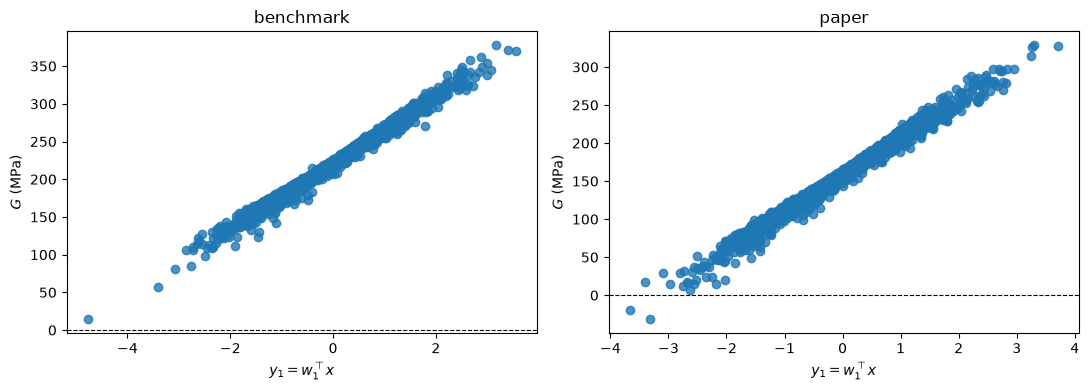

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, CONFIGS):
    ac.plotting.plot_sufficient_summary(subs[c], X=data[c]['U'], f=data[c]['f'], qoi_label='$G$ (MPa)', ax=ax)
    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.set_title(c)
fig.tight_layout()
plt.close(fig)
fig

Both plots show a nearly linear trend in $y_1$ with a narrow band; failure ($G \le 0$) is reached only at the low end of $y_1$, by 2 `paper` samples and no `benchmark` sample. The leave-one-out $R^2$ of polynomials in $y_1$ (next cell) quantifies the band.

In [13]:
loo = {}
for c in CONFIGS:
    for deg in (1, 2, 3):
        s = ac.fit_surrogate(X=data[c]['U'], f=data[c]['f'], space=space, subspace=subs[c], kind='poly', degree=deg)
        loo[(c, deg)] = s.loo_r_squared
    s9 = ac.fit_surrogate(X=data[c]['U'], f=data[c]['f'], space=space, subspace=None, kind='poly', degree=1)
    print(f'{c}: LOO R^2 of a polynomial in y1, degree 1, 2, 3: '
          + ', '.join(f'{loo[(c, d)]:.5f}' for d in (1, 2, 3)) + f'; linear in all 9 u: {s9.loo_r_squared:.5f}')

benchmark: LOO R^2 of a polynomial in y1, degree 1, 2, 3: 0.98772, 0.98771, 0.98768; linear in all 9 u: 0.98768
paper: LOO R^2 of a polynomial in y1, degree 1, 2, 3: 0.98508, 0.98537, 0.98532; linear in all 9 u: 0.98498


A linear function of $y_1$ has leave-one-out $R^2$ = 0.98772 (`benchmark`) and 0.98508 (`paper`); degree 2 or 3 does not improve it (0.98771 and 0.98537 at degree 2), and a linear fit in all nine $u_i$ is no better (0.98768 and 0.98498). So $G$ is nearly linear in $\mathbf u$; the remaining 1.2–1.5 % of the variance is nonlinearity spread over the other eight directions ($\mathbf w_2$ combines $F_s$, the two Gumbel loads and $D$). **Dimension: we choose $n = 1$** from the gap $\lambda_1/\lambda_2 \approx 89$, the small bootstrap error of $\mathbf w_1$ against the much larger one for $n = 2$, the absence of a second gap, and the $R^2$ of the one-variable fit.

### Failure probability by Monte Carlo

The paper reports reliability indices (FORM; p. 327), not failure probabilities. We estimate $P_f = P(G \le 0)$ by plain Monte Carlo (fresh draws, `default_rng(SEED)`; $2\times10^6$ for `paper`, $10^7$ for `benchmark`) with 95 % Clopper–Pearson intervals, and compare with the FORM value $\Phi(-\beta)$.

In [14]:
def mc_pf(config, N, chunk=10**6, rng=None):
    mg = sm.Marginals(config)
    nf = 0
    for k in range(N // chunk):
        _, X = mg.sample(chunk, rng)
        nf += int(np.sum(sm.limit_state(X) <= 0))
    p = nf / N
    lo, hi = stats.beta.ppf([0.025, 0.975], [nf, nf + 1], [N - nf + 1, N - nf]) if nf > 0 else (0.0, 3.689 / N)
    return nf, p, lo, hi
rng = np.random.default_rng(SEED)
t0 = time.perf_counter()
mc = {'paper': mc_pf('paper', 2 * 10**6, rng=rng), 'benchmark': mc_pf('benchmark', 10**7, rng=rng)}
for c in CONFIGS:
    nf, p, lo, hi = mc[c]
    print(f'{c}: {nf} failures in {"2e6" if c == "paper" else "1e7"} Monte Carlo draws, Pf = {p:.4e}, '
          f'95% Clopper-Pearson interval [{lo:.4e}, {hi:.4e}]; beta = -Phi^-1(Pf) = {-stats.norm.ppf(p):.4f} '
          f'[{-stats.norm.ppf(hi):.4f}, {-stats.norm.ppf(lo):.4f}]')
    print(f'   FORM Phi(-beta) = {stats.norm.cdf(-form_res[c][0]):.4e}; MC Pf / FORM Pf = {p / stats.norm.cdf(-form_res[c][0]):.3f}')
print(f'paper beta* = 3.132 (p. 327) -> Phi(-3.132) = {stats.norm.cdf(-3.132):.4e}; ({time.perf_counter() - t0:.0f} s)')

benchmark: 37 failures in 1e7 Monte Carlo draws, Pf = 3.7000e-06, 95% Clopper-Pearson interval [2.6051e-06, 5.1000e-06]; beta = -Phi^-1(Pf) = 4.4818 [4.4129, 4.5561]
   FORM Phi(-beta) = 2.1550e-06; MC Pf / FORM Pf = 1.717
paper: 2487 failures in 2e6 Monte Carlo draws, Pf = 1.2435e-03, 95% Clopper-Pearson interval [1.1951e-03, 1.2933e-03]; beta = -Phi^-1(Pf) = 3.0249 [3.0130, 3.0369]
   FORM Phi(-beta) = 8.6783e-04; MC Pf / FORM Pf = 1.433
paper beta* = 3.132 (p. 327) -> Phi(-3.132) = 8.6810e-04; (13 s)


For the paper's design Monte Carlo gives $P_f = 1.2435\times10^{-3}$ (95 % interval $[1.1951, 1.2933]\times10^{-3}$, generalized index $-\Phi^{-1}(P_f)$ = 3.0249), against the FORM value $\Phi(-3.1321) = 8.6783\times10^{-4}$ computed here ($\Phi(-3.132) = 8.6810\times10^{-4}$ from the paper's printed index): FORM underestimates the failure probability by a factor of 1.433, an effect of the curvature of the limit state in $\mathbf u$ that a first-order method does not capture. For `benchmark`, 37 failures in $10^7$ draws give $P_f = 3.70\times10^{-6}$ (interval $[2.61, 5.10]\times10^{-6}$), 1.717 times the FORM value $2.1550\times10^{-6}$.

### Comparison with the paper

| quantity | paper (page) | this notebook |
|---|---|---|
| number of random inputs | 9, $\mathbf X = (F_s, P_1, P_2, P_3, B, D, H, F_0, E)$ (p. 326) | 9 |
| design variables | means $(b, d, h)$, optimized (pp. 326–327) | fixed: $(300, 20, 300)$ (`benchmark`), $(200, 17.5, 100)$ (`paper`) |
| mean of $E$ | 21000 MPa (table, p. 326) | 210000 (`benchmark`), 21000 (`paper`) |
| reliability index at $(200, 17.5, 100)$ | 3.132 (p. 327) | FORM 3.1321 |
| reliability indices of the ten optimal designs | p. 327 ($E$ mean 21000 MPa, table p. 326) | FORM with $E$ 21000 / 4200 MPa: largest difference 0.0042; with $E$ 210000 / 4200 MPa: differences 0.699 to 10.402 (8 of 10 converged) |
| $h^*$ at its lower bound 100 mm | up to cost 12000 (table, p. 327); "up to … 12 500 CU" (p. 328) | $\beta$ falls with $h$ along the cost line (3.1321 → 2.1431 at cost 4000, 10.7048 → 10.5605 at cost 12000) |
| failure probability at $(200, 17.5, 100)$ | not reported ($\Phi(-3.132) = 8.6810\times10^{-4}$) | Monte Carlo $1.2435\times10^{-3}$, 95 % $[1.1951, 1.2933]\times10^{-3}$ |
| reliability index, `benchmark` design | not reported | FORM 4.5958; Monte Carlo $P_f = 3.70\times10^{-6}$ |
| active subspace | not reported | $n = 1$, $\lambda_1/\lambda_2$ = 88.99 and 88.10 |

### References

1. <a id="R1"></a>N. Kuschel and R. Rackwitz, "Two basic problems in reliability-based structural optimization", *Mathematical Methods of Operations Research* 46(3):309–333, 1997. https://doi.org/10.1007/BF01194859
2. <a id="R2"></a>P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. https://doi.org/10.1137/1.9781611973860
3. <a id="R3"></a>S. Surjanovic and D. Bingham, "Steel column function", Virtual Library of Simulation Experiments: Test Functions and Datasets, Simon Fraser University. https://www.sfu.ca/~ssurjano/steelcol.html
4. <a id="R4"></a>M. S. Eldred, C. G. Webster and P. G. Constantine, "Evaluation of non-intrusive approaches for Wiener–Askey generalized polynomial chaos", 49th AIAA/ASME/ASCE/AHS/ASC Structures, Structural Dynamics, and Materials Conference, Schaumburg, IL, 2008, AIAA 2008-1892. https://doi.org/10.2514/6.2008-1892

[R1]: https://doi.org/10.1007/BF01194859
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://www.sfu.ca/~ssurjano/steelcol.html
[R4]: https://doi.org/10.2514/6.2008-1892

In [15]:
print(f'notebook run time {time.perf_counter() - t_start:.0f} s')

notebook run time 33 s
